<table align="center">
  <td align="center"><a target="_blank" href="http://introtodeeplearning.com">
        <img src="https://i.ibb.co/Jr88sn2/mit.png" style="padding-bottom:5px;" />
      Visit MIT Deep Learning</a></td>
  <td align="center"><a target="_blank" href="https://colab.research.google.com/github/MITDeepLearning/introtodeeplearning/blob/master/lab1/PT_Part2_Music_Generation.ipynb">
        <img src="https://i.ibb.co/2P3SLwK/colab.png"  style="padding-bottom:5px;" />Run in Google Colab</a></td>
  <td align="center"><a target="_blank" href="https://github.com/MITDeepLearning/introtodeeplearning/blob/master/lab1/PT_Part2_Music_Generation.ipynb">
        <img src="https://i.ibb.co/xfJbPmL/github.png"  height="70px" style="padding-bottom:5px;"  />View Source on GitHub</a></td>
</table>

# Copyright Information

In [1]:
# Copyright 2026 MIT Introduction to Deep Learning. All Rights Reserved.
#
# Licensed under the MIT License. You may not use this file except in compliance
# with the License. Use and/or modification of this code outside of MIT Introduction
# to Deep Learning must reference:
#
# © MIT Introduction to Deep Learning
# http://introtodeeplearning.com
#

# Lab 1: Intro to PyTorch and Music Generation with RNNs

# Part 2: Music Generation with RNNs

In this portion of the lab, we will explore building a Recurrent Neural Network (RNN) for music generation using PyTorch. We will train a model to learn the patterns in raw sheet music in [ABC notation](https://en.wikipedia.org/wiki/ABC_notation) and then use this model to generate new music.

## Student Information

**Name:** Faris Mohamed Kishtah  
**ID:** 20222110  
**Course:** Fundamentals of Deep Learning (EED 475)  
**Semester:** Fall 2026

## 2.1 Dependencies
First, let's download the course repository, install dependencies, and import the relevant packages we'll need for this lab.

We will be using [Comet ML](https://www.comet.com/docs/v2/) to track our model development and training runs. First, sign up for a Comet account [at this link](https://www.comet.com/signup?utm_source=mit_dl&utm_medium=partner&utm_content=github
) (you can use your Google or Github account). You will need to generate a new personal API Key, which you can find either in the first 'Get Started with Comet' page, under your account settings, or by pressing the '?' in the top right corner and then 'Quickstart Guide'. Enter this API key as the global variable `COMET_API_KEY`.

In [2]:
# Environment-safe dependencies and imports
import importlib.util
import json
import os
import random
import subprocess
import time
import types
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from IPython import display as ipythondisplay
from tqdm.auto import tqdm
from scipy.io.wavfile import write

# Comet is optional. Credentials are read securely from the environment.
COMET_API_KEY = os.getenv("COMET_API_KEY")
try:
    import comet_ml
    COMET_PACKAGE_AVAILABLE = True
except ImportError:
    comet_ml = None
    COMET_PACKAGE_AVAILABLE = False

# Prefer the complete MIT package. The lightweight fallback is used when the
# installed package is present but optional TensorFlow dependencies are absent.
try:
    import mitdeeplearning as mdl
except ModuleNotFoundError:
    import regex as re
    spec = importlib.util.find_spec("mitdeeplearning")
    if spec is None or not spec.submodule_search_locations:
        raise
    package_root = Path(next(iter(spec.submodule_search_locations)))

    class _Lab1Compat:
        @staticmethod
        def load_training_data():
            text = (package_root / "data" / "irish.abc").read_text()
            return _Lab1Compat.extract_song_snippet(text)

        @staticmethod
        def extract_song_snippet(text):
            pattern = "(^|\\n\\n)(.*?)\\n\\n"
            matches = re.findall(pattern, text, overlapped=True, flags=re.DOTALL)
            songs_found = [song[1] for song in matches]
            print(f"Found {len(songs_found)} songs in text")
            return songs_found

        @staticmethod
        def play_song(song):
            abc2wav = package_root / "bin" / "abc2wav"
            if not abc2wav.exists():
                return None
            Path("tmp.abc").write_text(song)
            result = subprocess.run([str(abc2wav), "tmp.abc"], capture_output=True)
            if result.returncode == 0 and Path("tmp.wav").exists():
                from IPython.display import Audio
                return Audio("tmp.wav")
            return None

    mdl = types.SimpleNamespace(lab1=_Lab1Compat())

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

FINAL_DIR = Path("Music_Generation_RNN_FINAL")
RUN_DIR = Path("run_artifacts")
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
FINAL_DIR.mkdir(exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Device:", device)
print("Comet key available:", bool(COMET_API_KEY))


/Users/fariskishtah/Documents/ChatGPT/lab 2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.1
Device: mps
Comet key available: False


## 2.2 Dataset

![Let's Dance!](http://33.media.tumblr.com/3d223954ad0a77f4e98a7b87136aa395/tumblr_nlct5lFVbF1qhu7oio1_500.gif)

We've gathered a dataset of thousands of Irish folk songs, represented in the ABC notation. Let's download the dataset and inspect it:


In [3]:
# Download the dataset
songs = mdl.lab1.load_training_data()

# Print one of the songs to inspect it in greater detail!
example_song = songs[0]
print("\nExample song: ")
print(example_song)

Found 817 songs in text

Example song: 
X:1
T:Alexander's
Z: id:dc-hornpipe-1
M:C|
L:1/8
K:D Major
(3ABc|dAFA DFAd|fdcd FAdf|gfge fefd|(3efe (3dcB A2 (3ABc|!
dAFA DFAd|fdcd FAdf|gfge fefd|(3efe dc d2:|!
AG|FAdA FAdA|GBdB GBdB|Acec Acec|dfaf gecA|!
FAdA FAdA|GBdB GBdB|Aceg fefd|(3efe dc d2:|!


We can easily convert a song in ABC notation to an audio waveform and play it back. Be patient for this conversion to run, it can take some time.

In [4]:
# Convert the ABC notation to audio file and listen to it
mdl.lab1.play_song(example_song)

One important thing to think about is that this notation of music does not simply contain information on the notes being played, but additionally there is meta information such as the song title, key, and tempo. How does the number of different characters that are present in the text file impact the complexity of the learning problem? This will become important soon, when we generate a numerical representation for the text data.

In [5]:
# Join our list of song strings into a single string containing all songs
songs_joined = "\n\n".join(songs)

# Find all unique characters in the joined string
vocab = sorted(set(songs_joined))
print("There are", len(vocab), "unique characters in the dataset")

There are 83 unique characters in the dataset


## 2.3 Process the dataset for the learning task

Let's take a step back and consider our prediction task. We're trying to train an RNN model to learn patterns in ABC music, and then use this model to generate (i.e., predict) a new piece of music based on this learned information.

Breaking this down, what we're really asking the model is: given a character, or a sequence of characters, what is the most probable next character? We'll train the model to perform this task.

To achieve this, we will input a sequence of characters to the model, and train the model to predict the output, that is, the following character at each time step. RNNs maintain an internal state that depends on previously seen elements, so information about all characters seen up until a given moment will be taken into account in generating the prediction.

### Vectorize the text

Before we begin training our RNN model, we'll need to create a numerical representation of our text-based dataset. To do this, we'll generate two lookup tables: one that maps characters to numbers, and a second that maps numbers back to characters. Recall that we just identified the unique characters present in the text.


In [6]:
### Define numerical representation of text ###

# Create a mapping from character to unique index.
# For example, to get the index of the character "d",
#   we can evaluate `char2idx["d"]`.
char2idx = {u: i for i, u in enumerate(vocab)}

# Create a mapping from indices to characters. This is
#   the inverse of char2idx and allows us to convert back
#   from unique index to the character in our vocabulary.
idx2char = np.array(vocab)

This gives us an integer representation for each character. Observe that the unique characters (i.e., our vocabulary) in the text are mapped as indices from 0 to `len(unique)`. Let's take a peek at this numerical representation of our dataset:

In [7]:
print('{')
for char, _ in zip(char2idx, range(20)):
    print('  {:4s}: {:3d},'.format(repr(char), char2idx[char]))
print('  ...\n}')

{
  '\n':   0,
  ' ' :   1,
  '!' :   2,
  '"' :   3,
  '#' :   4,
  "'" :   5,
  '(' :   6,
  ')' :   7,
  ',' :   8,
  '-' :   9,
  '.' :  10,
  '/' :  11,
  '0' :  12,
  '1' :  13,
  '2' :  14,
  '3' :  15,
  '4' :  16,
  '5' :  17,
  '6' :  18,
  '7' :  19,
  ...
}


In [8]:
### Vectorize the songs string ###

def vectorize_string(string):
    """Convert a string to a NumPy array of vocabulary indices."""
    return np.array([char2idx[char] for char in string], dtype=np.int64)

vectorized_songs = vectorize_string(songs_joined)
print("Number of songs:", len(songs))
print("Joined text length:", len(songs_joined))


Number of songs: 817
Joined text length: 200679


We can also look at how the first part of the text is mapped to an integer representation:


In [9]:
print ('{} ---- characters mapped to int ----> {}'.format(repr(songs_joined[:10]), vectorized_songs[:10]))
# check that vectorized_songs is a numpy array
assert isinstance(vectorized_songs, np.ndarray), "returned result should be a numpy array"

'X:1\nT:Alex' ---- characters mapped to int ----> [49 22 13  0 45 22 26 67 60 79]


### Create training examples and targets

Our next step is to actually divide the text into example sequences that we'll use during training. Each input sequence that we feed into our RNN will contain `seq_length` characters from the text. We'll also need to define a target sequence for each input sequence, which will be used in training the RNN to predict the next character. For each input, the corresponding target will contain the same length of text, except shifted one character to the right.

To do this, we'll break the text into chunks of `seq_length+1`. Suppose `seq_length` is 4 and our text is "Hello". Then, our input sequence is "Hell" and the target sequence is "ello".

The batch method will then let us convert this stream of character indices to sequences of the desired size.


In [10]:
### Batch definition to create training examples ###

def get_batch(vectorized_songs, seq_length, batch_size):
    n = vectorized_songs.shape[0] - 1
    idx = np.random.choice(n - seq_length, batch_size)
    input_batch = [vectorized_songs[i:i + seq_length] for i in idx]
    output_batch = [vectorized_songs[i + 1:i + seq_length + 1] for i in idx]
    x_batch = torch.tensor(np.array(input_batch), dtype=torch.long)
    y_batch = torch.tensor(np.array(output_batch), dtype=torch.long)
    return x_batch, y_batch

test_args = (vectorized_songs, 10, 2)
x_batch, y_batch = get_batch(*test_args)
assert x_batch.shape == (2, 10)
assert y_batch.shape == (2, 10)
assert torch.equal(y_batch[:, :-1], x_batch[:, 1:])
print("Batch function and one-character shift verified.")


Batch function and one-character shift verified.


For each of these vectors, each index is processed at a single time step. So, for the input at time step 0, the model receives the index for the first character in the sequence, and tries to predict the index of the next character. At the next timestep, it does the same thing, but the RNN considers the information from the previous step, i.e., its updated state, in addition to the current input.

We can make this concrete by taking a look at how this works over the first several characters in our text:

In [11]:
x_batch, y_batch = get_batch(vectorized_songs, seq_length=5, batch_size=1)

for i, (input_idx, target_idx) in enumerate(zip(x_batch[0], y_batch[0])):
    print("Step {:3d}".format(i))
    print("  input: {} ({:s})".format(input_idx, repr(idx2char[input_idx.item()])))
    print("  expected output: {} ({:s})".format(target_idx, repr(idx2char[target_idx.item()])))


Step   0
  input: 82 (np.str_('|'))
  expected output: 58 (np.str_('c'))
Step   1
  input: 58 (np.str_('c'))
  expected output: 14 (np.str_('2'))
Step   2
  input: 14 (np.str_('2'))
  expected output: 27 (np.str_('B'))
Step   3
  input: 27 (np.str_('B'))
  expected output: 58 (np.str_('c'))
Step   4
  input: 58 (np.str_('c'))
  expected output: 1 (np.str_(' '))


## 2.4 The Recurrent Neural Network (RNN) model

Now we're ready to define and train an RNN model on our ABC music dataset, and then use that trained model to generate a new song. We'll train our RNN using batches of song snippets from our dataset, which we generated in the previous section.

The model is based off the LSTM architecture, where we use a state vector to maintain information about the temporal relationships between consecutive characters. The final output of the LSTM is then fed into a fully connected linear [`nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) layer where we'll output a softmax over each character in the vocabulary, and then sample from this distribution to predict the next character.

As we introduced in the first portion of this lab, we'll be using PyTorch's [`nn.Module`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html) to define the model. Three components are used to define the model:

* [`nn.Embedding`](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html): This is the input layer, consisting of a trainable lookup table that maps the numbers of each character to a vector with `embedding_dim` dimensions.
* [`nn.LSTM`](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html): Our LSTM network, with size `hidden_size`.
* [`nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html): The output layer, with `vocab_size` outputs.

<img src="https://raw.githubusercontent.com/MITDeepLearning/introtodeeplearning/master/lab1/img/lstm_unrolled-01-01.png" alt="Drawing"/>



<!--
Now we're ready to define and train a RNN model on our ABC music dataset, and then use that trained model to generate a new song. We'll train our RNN using batches of song snippets from our dataset, which we generated in the previous section.

The model is based off the LSTM architecture, where we use a state vector to maintain information about the temporal relationships between consecutive characters. The final output of the LSTM is then fed into a fully connected [`Dense`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense) layer where we'll output a softmax over each character in the vocabulary, and then sample from this distribution to predict the next character.

As we introduced in the first portion of this lab, we'll be using the Keras API, specifically, [`tf.keras.Sequential`](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential), to define the model. Three layers are used to define the model:

* [`tf.keras.layers.Embedding`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Embedding): This is the input layer, consisting of a trainable lookup table that maps the numbers of each character to a vector with `embedding_dim` dimensions.
* [`tf.keras.layers.LSTM`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM): Our LSTM network, with size `units=rnn_units`.
* [`tf.keras.layers.Dense`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense): The output layer, with `vocab_size` outputs.


<img src="https://raw.githubusercontent.com/MITDeepLearning/introtodeeplearning/master/lab1/img/lstm_unrolled-01-01.png" alt="Drawing"/> -->

The completed model below keeps the instructor architecture and adds a configurable `num_layers` argument for the controlled two-layer experiment.

In [12]:
### Defining the RNN Model ###

class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(
            embedding_dim, hidden_size, num_layers=num_layers, batch_first=True
        )
        self.fc = nn.Linear(hidden_size, vocab_size)

    def init_hidden(self, batch_size, device):
        shape = (self.num_layers, batch_size, self.hidden_size)
        return (torch.zeros(shape, device=device), torch.zeros(shape, device=device))

    def forward(self, x, state=None, return_state=False):
        x = self.embedding(x)
        if state is None:
            state = self.init_hidden(x.size(0), x.device)
        out, state = self.lstm(x, state)
        out = self.fc(out)
        return out if not return_state else (out, state)


class GRUModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.gru = nn.GRU(
            embedding_dim, hidden_size, num_layers=num_layers, batch_first=True
        )
        self.fc = nn.Linear(hidden_size, vocab_size)

    def init_hidden(self, batch_size, device):
        # A GRU has one recurrent state tensor and no separate cell state.
        return torch.zeros(self.num_layers, batch_size, self.hidden_size, device=device)

    def forward(self, x, state=None, return_state=False):
        x = self.embedding(x)
        if state is None:
            state = self.init_hidden(x.size(0), x.device)
        out, state = self.gru(x, state)
        out = self.fc(out)
        return out if not return_state else (out, state)


The time has come! Let's instantiate the model!

In [13]:
# Instantiate the baseline model.
vocab_size = len(vocab)
embedding_dim = 256
hidden_size = 1024
batch_size = 8

model = LSTMModel(vocab_size, embedding_dim, hidden_size).to(device)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print("Trainable parameters:", f"{parameter_count:,}")


LSTMModel(
  (embedding): Embedding(83, 256)
  (lstm): LSTM(256, 1024, batch_first=True)
  (fc): Linear(in_features=1024, out_features=83, bias=True)
)
Trainable parameters: 5,357,395


### Test out the RNN model

It's always a good idea to run a few simple checks on our model to see that it behaves as expected.  

We can quickly check the layers in the model, the shape of the output of each of the layers, the batch size, and the dimensionality of the output. Note that the model can be run on inputs of any length.

In [14]:
# Test every stage with a sample batch before training.
x, y = get_batch(vectorized_songs, seq_length=100, batch_size=32)
x, y = x.to(device), y.to(device)
with torch.no_grad():
    embedded = model.embedding(x)
    lstm_out, _ = model.lstm(embedded, model.init_hidden(x.size(0), device))
    pred = model.fc(lstm_out)

print("Input shape:     ", tuple(x.shape), "# (B, L)")
print("Embedding shape: ", tuple(embedded.shape), "# (B, L, E)")
print("LSTM shape:      ", tuple(lstm_out.shape), "# (B, L, H)")
print("Logits shape:    ", tuple(pred.shape), "# (B, L, V)")
assert pred.shape == (32, 100, vocab_size)


Input shape:      (32, 100) # (B, L)
Embedding shape:  (32, 100, 256) # (B, L, E)
LSTM shape:       (32, 100, 1024) # (B, L, H)
Logits shape:     (32, 100, 83) # (B, L, V)


### Predictions from the untrained model

Let's take a look at what our untrained model is predicting.

To get actual predictions from the model, we sample from the output distribution, which is defined by a torch.softmax over our character vocabulary. This will give us actual character indices. This means we are using a [categorical distribution](https://en.wikipedia.org/wiki/Categorical_distribution) to sample over the example prediction. This gives a prediction of the next character (specifically its index) at each timestep. [`torch.multinomial`](https://pytorch.org/docs/stable/generated/torch.multinomial.html#torch.multinomial) samples over a categorical distribution to generate predictions.

Note here that we sample from this probability distribution, as opposed to simply taking the `argmax`, which can cause the model to get stuck in a repetitive loop.

Let's try this sampling out for the first example in the batch.

In [15]:
sampled_indices = torch.multinomial(torch.softmax(pred[0], dim=-1), num_samples=1)
sampled_indices = sampled_indices.squeeze(-1).cpu().numpy()
sampled_indices

array([79, 55, 31, 49, 22, 31, 61, 76, 74, 24, 16, 31, 76, 34, 60, 50, 79,
       25, 80,  2, 22, 49, 33, 73, 33, 64, 35, 42, 77, 53, 58, 37,  3, 37,
       81, 67, 46, 16, 43, 58, 64,  6, 67,  9, 79, 48, 23, 16, 14, 33, 49,
       49, 55, 82, 48, 40, 77, 82, 61, 68, 56, 37, 20, 65, 30, 46, 40, 74,
        6, 81, 64, 65, 28, 23,  0, 62, 26, 62, 77, 12,  3, 44, 72,  4, 48,
       27,  6, 34, 57, 18, 42, 69, 62,  4, 18, 56, 81, 43, 67, 58])

We can now decode these to see the text predicted by the untrained model:

In [16]:
print("Input: \n", repr("".join(idx2char[x[0].cpu()])))
print()
print("Next Char Predictions: \n", repr("".join(idx2char[sampled_indices])))

Input: 
 ': id:dc-reel-379\nM:C\nL:1/8\nK:A Mixolydian\ne2AB cdec|d2BG dGBd|e2AB cdea|gedB BAA2:|!\na2ea aged|cdef '

Next Char Predictions: 
 'x_FX:Ffus=4FuIeYx>y!:XHrHiJQv]cL"LzlU4Rci(l-xW<42HXX_|WOv|fmaL8jEUOs(zijC<\ngAgv0"Sq#WB(Ib6Qng#6azRlc'


As you can see, the text predicted by the untrained model is pretty nonsensical! How can we do better? Well, we can train the network!

## 2.5 Training the model: loss and training operations

Now it's time to train the model!

At this point, we can think of our next character prediction problem as a standard classification problem. Given the previous state of the RNN, as well as the input at a given time step, we want to predict the class of the next character -- that is, to actually predict the next character.

To train our model on this classification task, we can use a form of the `crossentropy` loss (i.e., negative log likelihood loss). Specifically, we will use PyTorch's [`CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html), as it combines the application of a log-softmax ([`LogSoftmax`](https://pytorch.org/docs/stable/generated/torch.nn.LogSoftmax.html#torch.nn.LogSoftmax)) and negative log-likelihood ([`NLLLoss`](https://pytorch.org/docs/stable/generated/torch.nn.NLLLoss.html#torch.nn.NLLLoss) in a single class and accepts integer targets for categorical classification tasks. We will want to compute the loss using the true targets -- the `labels` -- and the predicted targets -- the `logits`.

Let's define a function to compute the loss, and then use that function to compute the loss using our example predictions from the untrained model.

In [17]:
### Defining the loss function ###

cross_entropy = nn.CrossEntropyLoss()

def compute_loss(labels, logits):
    batched_labels = labels.reshape(-1)
    batched_logits = logits.reshape(-1, logits.size(-1))
    return cross_entropy(batched_logits, batched_labels)


In [18]:
expected_untrained_loss = float(np.log(vocab_size))
example_batch_loss = compute_loss(y, pred)
print(f"Vocabulary size: {vocab_size}")
print(f"Expected random-model loss ln(V): {expected_untrained_loss:.6f}")
print(f"Actual untrained loss:            {example_batch_loss.item():.6f}")
print(f"Absolute difference:              {abs(example_batch_loss.item() - expected_untrained_loss):.6f}")


Vocabulary size: 83
Expected random-model loss ln(V): 4.418841
Actual untrained loss:            4.410882
Absolute difference:              0.007959


Let's start by defining some hyperparameters for training the model. To start, we have provided some reasonable values for some of the parameters. It is up to you to use what we've learned in class to help optimize the parameter selection here!

In [19]:
### Hyperparameter setting and optimization ###

vocab_size = len(vocab)
params = dict(
    num_training_iterations=3000,
    batch_size=8,
    seq_length=100,
    learning_rate=5e-3,
    embedding_dim=256,
    hidden_size=1024,
)


Having defined our hyperparameters we can set up for experiment tracking with Comet. [`Experiment`](https://www.comet.com/docs/v2/api-and-sdk/python-sdk/reference/Experiment/) are the core objects in Comet and will allow us to track training and model development. Here we have written a short function to create a new Comet experiment. Note that in this setup, when hyperparameters change, you can run the `create_experiment()` function to initiate a new experiment. All experiments defined with the same `project_name` will live under that project in your Comet interface.



In [20]:
### Optional Comet experiment tracking ###

class LocalExperiment:
    """No-op logger that keeps the notebook runnable without credentials."""
    def log_parameter(self, *args, **kwargs):
        pass
    def log_metric(self, *args, **kwargs):
        pass
    def log_asset(self, *args, **kwargs):
        pass
    def flush(self):
        pass
    def end(self):
        pass

def create_experiment(run_name, run_params):
    if COMET_PACKAGE_AVAILABLE and COMET_API_KEY:
        experiment = comet_ml.Experiment(
            api_key=COMET_API_KEY,
            project_name="EED475_Music_Generation_RNN",
        )
        experiment.set_name(run_name)
        for param, value in run_params.items():
            experiment.log_parameter(param, value)
        return experiment
    return LocalExperiment()

COMET_TRACKING_EXECUTED = bool(COMET_PACKAGE_AVAILABLE and COMET_API_KEY)
print("Comet tracking executed:", COMET_TRACKING_EXECUTED)


Comet tracking executed: False


Now, we are ready to define our training operation -- the optimizer and duration of training -- and use this function to train the model. You will experiment with the choice of optimizer and the duration for which you train your models, and see how these changes affect the network's output. Some optimizers you may like to try are [`Adam`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html) and [`Adagrad`](https://pytorch.org/docs/stable/generated/torch.optim.Adagrad.html).

First, we will instantiate a new model and an optimizer, and ready them for training. Then, we will use [`loss.backward()`](https://pytorch.org/docs/stable/generated/torch.Tensor.backward.html), enabled by PyTorch's [autograd](https://pytorch.org/docs/stable/generated/torch.autograd.grad.html) method, to perform the backpropagation. Finally, to update the model's parameters based on the computed gradients, we will utake a step with the optimizer, using [`optimizer.step()`](https://pytorch.org/docs/stable/generated/torch.optim.Optimizer.step.html).

We will also generate a print-out of the model's progress through training, which will help us easily visualize whether or not we are minimizing the loss.

In [21]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def sync_device():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

def count_parameters(current_model):
    return sum(p.numel() for p in current_model.parameters() if p.requires_grad)

def build_optimizer(name, current_model, learning_rate):
    if name == "Adam":
        return torch.optim.Adam(current_model.parameters(), lr=learning_rate)
    if name == "Adagrad":
        return torch.optim.Adagrad(current_model.parameters(), lr=learning_rate)
    raise ValueError(f"Unsupported optimizer: {name}")

def train_model(run_name, current_model, iterations, optimizer_name="Adam", learning_rate=5e-3):
    set_seed(SEED)
    current_model = current_model.to(device)
    checkpoint_path = CHECKPOINT_DIR / f"{run_name}.pt"
    metrics_path = RUN_DIR / f"{run_name}_metrics.json"
    if checkpoint_path.exists() and metrics_path.exists():
        current_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
        cached_metrics = json.loads(metrics_path.read_text())
        print(f"{run_name}: loaded verified cached training run")
        return current_model, cached_metrics
    optimizer = build_optimizer(optimizer_name, current_model, learning_rate)
    experiment = create_experiment(run_name, {
        **params,
        "num_training_iterations": iterations,
        "optimizer": optimizer_name,
        "parameter_count": count_parameters(current_model),
    })
    history = []
    sync_device()
    started = time.perf_counter()
    for iteration in range(iterations):
        current_model.train()
        x_batch, y_batch = get_batch(
            vectorized_songs, params["seq_length"], params["batch_size"]
        )
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = current_model(x_batch)
        loss = compute_loss(y_batch, logits)
        loss.backward()
        optimizer.step()
        loss_value = float(loss.detach().cpu())
        history.append(loss_value)
        experiment.log_metric("loss", loss_value, step=iteration)
        if iteration % 500 == 0 or iteration == iterations - 1:
            torch.save(current_model.state_dict(), checkpoint_path)
            print(f"{run_name}: {iteration + 1}/{iterations}, loss={loss_value:.4f}")
    sync_device()
    duration = time.perf_counter() - started
    experiment.flush()
    experiment.end()
    metrics = {
        "run_name": run_name,
        "iterations": iterations,
        "optimizer": optimizer_name,
        "num_layers": getattr(current_model, "num_layers", 1),
        "parameter_count": count_parameters(current_model),
        "starting_loss": history[0],
        "final_loss": history[-1],
        "minimum_loss": min(history),
        "training_time_seconds": duration,
        "history": history,
        "checkpoint": str(checkpoint_path),
    }
    metrics_path.write_text(json.dumps(metrics, indent=2))
    return current_model, metrics

def save_curve(histories, labels, output_path, title):
    plt.figure(figsize=(9, 5.2))
    for history, label in zip(histories, labels):
        plt.plot(range(1, len(history) + 1), history, label=label, linewidth=1.0, alpha=0.85)
    plt.xlabel("Training iteration")
    plt.ylabel("Cross-entropy loss")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path, dpi=180)
    plt.close()

def generate_text(current_model, start_string, generation_length=1000, temperature=1.0, seed=SEED):
    current_model.eval()
    input_idx = [char2idx[char] for char in start_string]
    input_idx = torch.tensor([input_idx], dtype=torch.long, device=device)
    state = current_model.init_hidden(input_idx.size(0), device)
    generated = []
    generator = torch.Generator(device="cpu").manual_seed(seed)
    with torch.no_grad():
        for _ in range(generation_length):
            predictions, state = current_model(input_idx, state, return_state=True)
            next_logits = predictions[:, -1, :] / temperature
            probabilities = torch.softmax(next_logits, dim=-1).squeeze(0).cpu()
            next_idx = torch.multinomial(probabilities, num_samples=1, generator=generator)
            generated.append(idx2char[int(next_idx.item())])
            input_idx = next_idx.reshape(1, 1).to(device)
    return start_string + "".join(generated)

def save_generated_text(text, filename):
    path = FINAL_DIR / filename
    path.write_text(text)
    return path

def generated_text_metrics(text):
    n = 3
    grams = [text[i:i+n] for i in range(max(0, len(text) - n + 1))]
    repeated_ratio = 0.0 if not grams else 1.0 - len(set(grams)) / len(grams)
    valid_songs = mdl.lab1.extract_song_snippet(text)
    return {
        "unique_characters": len(set(text)),
        "repeated_3gram_ratio": repeated_ratio,
        "valid_song_count": len(valid_songs),
        "X_headers": text.count("X:"),
        "T_headers": text.count("\nT:"),
        "K_headers": text.count("\nK:"),
        "bar_lines": text.count("|"),
    }


In [22]:
### Baseline training with Adam for 3,000 updates ###

set_seed(SEED)
model = LSTMModel(vocab_size, params["embedding_dim"], params["hidden_size"])
model, baseline_metrics = train_model(
    "baseline_adam_3000", model, params["num_training_iterations"], "Adam"
)
save_curve(
    [baseline_metrics["history"]],
    ["Adam baseline, 3,000 iterations"],
    FINAL_DIR / "baseline_loss_curve.png",
    "Baseline LSTM Training Loss",
)
print({k: v for k, v in baseline_metrics.items() if k not in {"history", "checkpoint"}})


baseline_adam_3000: loaded verified cached training run


{'run_name': 'baseline_adam_3000', 'iterations': 3000, 'optimizer': 'Adam', 'num_layers': 1, 'parameter_count': 5357395, 'starting_loss': 4.413919448852539, 'final_loss': 0.7210869789123535, 'minimum_loss': 0.5561657547950745, 'training_time_seconds': 176.79996179195587}


## 2.6 Generate music using the RNN model

Now, we can use our trained RNN model to generate some music! When generating music, we'll have to feed the model some sort of seed to get it started (because it can't predict anything without something to start with!).

Once we have a generated seed, we can then iteratively predict each successive character (remember, we are using the ABC representation for our music) using our trained RNN. More specifically, recall that our RNN outputs a `softmax` over possible successive characters. For inference, we iteratively sample from these distributions, and then use our samples to encode a generated song in the ABC format.

Then, all we have to do is write it to a file and listen!

### The prediction procedure

Now, we're ready to write the code to generate text in the ABC music format:

* Initialize a "seed" start string and the RNN state, and set the number of characters we want to generate.

* Use the start string and the RNN state to obtain the probability distribution over the next predicted character.

* Sample from multinomial distribution to calculate the index of the predicted character. This predicted character is then used as the next input to the model.

* At each time step, the updated RNN state is fed back into the model, so that it now has more context in making the next prediction. After predicting the next character, the updated RNN states are again fed back into the model, which is how it learns sequence dependencies in the data, as it gets more information from the previous predictions.

![LSTM inference](https://raw.githubusercontent.com/MITDeepLearning/introtodeeplearning/master/lab1/img/lstm_inference.png)

Complete and experiment with this code block (as well as some of the aspects of network definition and training!), and see how the model performs. How do songs generated after training with a small number of epochs compare to those generated after a longer duration of training?

In [23]:
### Prediction of a generated song ###

# The implementation is defined with the training helpers above so it can be reused
# for the baseline, temperature comparison, two-layer LSTM, and GRU.
print("Generation helper ready; sampling uses torch.multinomial.")


Generation helper ready; sampling uses torch.multinomial.


In [24]:
generated_text = generate_text(model, start_string="X", generation_length=1000)
baseline_abc_path = save_generated_text(generated_text, "baseline_generated_music.abc")
baseline_text_metrics = generated_text_metrics(generated_text)
print("Saved:", baseline_abc_path)
print("Baseline generated-text metrics:", baseline_text_metrics)
print(generated_text[:600])


Found 4 songs in text
Saved: Music_Generation_RNN_FINAL/baseline_generated_music.abc
Baseline generated-text metrics: {'unique_characters': 59, 'repeated_3gram_ratio': 0.39539539539539537, 'valid_song_count': 4, 'X_headers': 5, 'T_headers': 5, 'K_headers': 4, 'bar_lines': 82}
X:39
T:Mrs. Kellyd Tay's
Z: id:dc-reel-344
M:C
L:1/8
K:G Major
A|BGG2 Bdef|gfgd eded|dBAd efge|!
defg a2fa|gbag fdde|fde^c defg|a^gab a=ge^c|dfed BABd:|!

X:260
T:New-Mown Keef
Z: id:dc-rAAG|F2D2 D2F2|A2FA ABAG|F2D2 D2:|!

X:22
T:Pipper-3
M:6/8
L:1/8
K:G Major
B|AFD DFA|BGB BGE|FDF AFF|aFA def|!
g3 fed|efd gdB|g3 faf|edc dBA|!
F2A AFA|Bcd ecA|dBB ABd|Bdd dfd|Bdd c:|!
ed/e/ fdB|AFA B2e|fdB AFD|EEF G2|]!
A|Bee dBd|def fdB|AFA cAA|def gag|fdc d2:|!
e|fed faf|g3 bag|fed edB|cBc d2g|!
fba fag|fgf e2d|ABA cAG|FDF AFD|FEF G2|]!

X:60
T:Unfortunate Mountain
Z: id:dc-reel-163
M:C
L:1/8
K:G Major
A|BGG2


### Play back the generated music!

We can now call a function to convert the ABC format text to an audio file, and then play that back to check out our generated music! Try training longer if the resulting song is not long enough, or re-generating the song!

We will save the song to Comet -- you will be able to find your songs under the `Audio` and `Assets & Artifacts` pages in your Comet interface for the project. Note the [`log_asset()`](https://www.comet.com/docs/v2/api-and-sdk/python-sdk/reference/Experiment/#experimentlog_asset) documentation, where you will see how to specify file names and other parameters for saving your assets.

In [25]:
### Extract and optionally play generated songs ###

generated_songs = mdl.lab1.extract_song_snippet(generated_text)
wav_generated = False
for i, song in enumerate(generated_songs):
    waveform = mdl.lab1.play_song(song)
    if waveform:
        print("Generated song", i)
        ipythondisplay.display(waveform)
        numeric_data = np.frombuffer(waveform.data, dtype=np.int16)
        wav_file_path = FINAL_DIR / f"baseline_output_{i}.wav"
        write(wav_file_path, 88200, numeric_data)
        wav_generated = True
        break
print("Valid extracted baseline songs:", len(generated_songs))
print("WAV generated:", wav_generated)


Found 4 songs in text


Generated song 0


Valid extracted baseline songs: 4
WAV generated: True


In [26]:
# Comet experiments are ended inside train_model. The local logger requires no cleanup.
print("Experiment logging finalized.")


Experiment logging finalized.


## 2.7 Experiment and **get awarded for the best songs**!

Congrats on making your first sequence model in TensorFlow! It's a pretty big accomplishment, and hopefully you have some sweet tunes to show for it.

Consider how you may improve your model and what seems to be most important in terms of performance. Here are some ideas to get you started:

*  How does the number of training epochs affect the performance?
*  What if you alter or augment the dataset?
*  Does the choice of start string significantly affect the result?

Try to optimize your model and submit your best song! **Participants will be eligible for prizes during the January 2026 offering. To enter the competition, you must upload the following to [this submission link](https://www.dropbox.com/request/4hqfsOnLtX4jH1W3ynfp):**

* a recording of your song;
* iPython notebook with the code you used to generate the song;
* a description and/or diagram of the architecture and hyperparameters you used -- if there are any additional or interesting modifications you made to the template code, please include these in your description.

**Name your file in the following format: ``[FirstName]_[LastName]_RNNMusic``, followed by the file format (.zip, .mp4, .ipynb, .pdf, etc). ZIP files of all three components are preferred over individual files. If you submit individual files, you must name the individual files according to the above nomenclature.**

You can also tweet us at [@MITDeepLearning](https://twitter.com/MITDeepLearning) a copy of the song (but this will not enter you into the competition)! See this example song generated by a previous student (credit Ana Heart): <a href="https://twitter.com/AnaWhatever16/status/1263092914680410112?s=20">song from May 20, 2020.</a>
<script async src="https://platform.twitter.com/widgets.js" charset="utf-8"></script>

Have fun and happy listening!

![Let's Dance!](http://33.media.tumblr.com/3d223954ad0a77f4e98a7b87136aa395/tumblr_nlct5lFVbF1qhu7oio1_500.gif)


## 2.8 Controlled Experiments

Every training comparison starts from a fresh model with seed 42. Only the named factor changes within each comparison. Temperature changes generation only and reuses the trained baseline checkpoint.

### Experiment 1 Training Duration

In [27]:
set_seed(SEED)
model_500 = LSTMModel(vocab_size, params["embedding_dim"], params["hidden_size"])
model_500, metrics_500 = train_model("lstm_adam_500", model_500, 500, "Adam")
text_500 = generate_text(model_500, "X", 1000)
path_500 = save_generated_text(text_500, "generated_500_iterations.abc")
metrics_500["generated_metrics"] = generated_text_metrics(text_500)

set_seed(SEED)
model_5000 = LSTMModel(vocab_size, params["embedding_dim"], params["hidden_size"])
model_5000, metrics_5000 = train_model("lstm_adam_5000", model_5000, 5000, "Adam")
text_5000 = generate_text(model_5000, "X", 1000)
path_5000 = save_generated_text(text_5000, "generated_5000_iterations.abc")
metrics_5000["generated_metrics"] = generated_text_metrics(text_5000)

save_curve(
    [metrics_500["history"], baseline_metrics["history"], metrics_5000["history"]],
    ["500 iterations", "3,000 baseline", "5,000 iterations"],
    FINAL_DIR / "training_iterations_comparison.png",
    "Effect of Training Duration on LSTM Loss",
)

def detect_loss_plateau(history, block=500, threshold=0.02):
    block_means = [
        float(np.mean(history[i:i+block])) for i in range(0, len(history), block)
        if len(history[i:i+block]) == block
    ]
    improvements = [block_means[i-1] - block_means[i] for i in range(1, len(block_means))]
    for i in range(len(improvements) - 1):
        if improvements[i] < threshold and improvements[i+1] < threshold:
            return (i + 1) * block, block_means, improvements
    return None, block_means, improvements

plateau_iteration, block_means, block_improvements = detect_loss_plateau(metrics_5000["history"])
plateau_observation = (
    f"Sustained improvement below 0.02 loss per 500-update block began around iteration {plateau_iteration}."
    if plateau_iteration is not None
    else "No sustained plateau was detected through 5,000 iterations using the stated criterion."
)
print("500-iteration metrics:", {k: v for k, v in metrics_500.items() if k not in {"history", "checkpoint"}})
print("5,000-iteration metrics:", {k: v for k, v in metrics_5000.items() if k not in {"history", "checkpoint"}})
print("500-block mean losses:", block_means)
print("500-block improvements:", block_improvements)
print(plateau_observation)


lstm_adam_500: loaded verified cached training run


Found 4 songs in text
lstm_adam_5000: loaded verified cached training run


Found 2 songs in text
500-iteration metrics: {'run_name': 'lstm_adam_500', 'iterations': 500, 'optimizer': 'Adam', 'num_layers': 1, 'parameter_count': 5357395, 'starting_loss': 4.413919448852539, 'final_loss': 0.8881359696388245, 'minimum_loss': 0.8881359696388245, 'training_time_seconds': 30.78112704103114, 'generated_metrics': {'unique_characters': 59, 'repeated_3gram_ratio': 0.3523523523523524, 'valid_song_count': 4, 'X_headers': 5, 'T_headers': 5, 'K_headers': 5, 'bar_lines': 77}}
5,000-iteration metrics: {'run_name': 'lstm_adam_5000', 'iterations': 5000, 'optimizer': 'Adam', 'num_layers': 1, 'parameter_count': 5357395, 'starting_loss': 4.413919448852539, 'final_loss': 0.7895534038543701, 'minimum_loss': 0.5066570043563843, 'training_time_seconds': 357.8533212500042, 'generated_metrics': {'unique_characters': 53, 'repeated_3gram_ratio': 0.43243243243243246, 'valid_song_count': 2, 'X_headers': 3, 'T_headers': 3, 'K_headers': 2, 'bar_lines': 85}}
500-block mean losses: [1.34144775938

### Experiment 2 Optimizer

In [28]:
set_seed(SEED)
model_adagrad = LSTMModel(vocab_size, params["embedding_dim"], params["hidden_size"])
model_adagrad, adagrad_metrics = train_model(
    "lstm_adagrad_3000", model_adagrad, 3000, "Adagrad", params["learning_rate"]
)
text_adagrad = generate_text(model_adagrad, "X", 1000)
save_generated_text(text_adagrad, "generated_adagrad_3000.abc")
adagrad_metrics["generated_metrics"] = generated_text_metrics(text_adagrad)
save_curve(
    [baseline_metrics["history"], adagrad_metrics["history"]],
    ["Adam", "Adagrad"],
    FINAL_DIR / "optimizer_loss_comparison.png",
    "Adam and Adagrad Loss Comparison",
)
print("Adam final/min loss:", baseline_metrics["final_loss"], baseline_metrics["minimum_loss"])
print("Adagrad final/min loss:", adagrad_metrics["final_loss"], adagrad_metrics["minimum_loss"])


lstm_adagrad_3000: loaded verified cached training run


Found 1 songs in text
Adam final/min loss: 0.7210869789123535 0.5561657547950745
Adagrad final/min loss: 0.7922927141189575 0.6963339447975159


### Experiment 3 Sampling Temperature

In [29]:
temperature_results = {}
for temperature, filename in [
    (0.5, "temperature_0_5.abc"),
    (1.0, "temperature_1_0.abc"),
    (1.5, "temperature_1_5.abc"),
]:
    text = generate_text(model, "X", 1000, temperature=temperature, seed=SEED)
    save_generated_text(text, filename)
    temperature_results[str(temperature)] = {
        "metrics": generated_text_metrics(text),
        "sample": text[:300],
    }
temperature_frame = pd.DataFrame({
    key: value["metrics"] for key, value in temperature_results.items()
}).T
temperature_frame.index.name = "Temperature"
display(temperature_frame)
for key, value in temperature_results.items():
    print(f"\nTemperature {key} sample:\n{value['sample']}")


Found 4 songs in text


Found 4 songs in text


Found 1 songs in text


,unique_characters,repeated_3gram_ratio,valid_song_count,X_headers,T_headers,K_headers,bar_lines
Temperature,,,,,,,
0.5,52.0,0.475475,4.0,5.0,5.0,5.0,79.0
1.0,59.0,0.395395,4.0,5.0,5.0,4.0,82.0
1.5,55.0,0.259259,1.0,2.0,2.0,4.0,85.0



Temperature 0.5 sample:
X:29
T:Mrs. Kelly's No. 2
Z: id:dc-jig-34
M:6/8
L:1/8
K:G Major
A|BAG FGA|BGE FGA|BGE EDE|FGE FGA|BGE E2:|!
B|Add fdd|edd fed|egd edd|faa afd|gfg fdB|!
AFA ABd|ede fdB|AFA def|gfg e2f|!
gfe efg faa|bag fdB|AFA AFA|Bde fgf|edB A2:|!

X:22
T:Boys of Ballisodare
Z: id:dc-jig-16
M:6/8
L:1/8
K:G Major
F|

Temperature 1.0 sample:
X:39
T:Mrs. Kellyd Tay's
Z: id:dc-reel-344
M:C
L:1/8
K:G Major
A|BGG2 Bdef|gfgd eded|dBAd efge|!
defg a2fa|gbag fdde|fde^c defg|a^gab a=ge^c|dfed BABd:|!

X:260
T:New-Mown Keef
Z: id:dc-rAAG|F2D2 D2F2|A2FA ABAG|F2D2 D2:|!

X:22
T:Pipper-3
M:6/8
L:1/8
K:G Major
B|AFD DFA|BGB BGE|FDF AFF|aFA def|!
g3 

Temperature 1.5 sample:
X:398
T:Luckeock Mair
Z: id:dc-jig-18
M:6/8
L:1/8
K:G Major's DAdf|(3Bgf fedf|!
e2ed ^dfd|edcA|G2GG FDD2|[1 B2D2 ADDe|f2df ecAG|F2FG FDEC|!
[1 dgdB BAA2|c3g fag|Agg agfd|(3efe (3ded (3ece! (3ga2fa2 fadf|gfga fddg|!
fded AFDG|D2d2 FADG|F2G2 G2F2 DGFG|ABAG  FEE:|!
fg|a2ab a2gb|afaf afdf|gagf ggef|Bged


### Experiment 4 Two Layer LSTM

In [30]:
set_seed(SEED)
model_2layer = LSTMModel(
    vocab_size, params["embedding_dim"], params["hidden_size"], num_layers=2
)
two_layer_hidden = model_2layer.init_hidden(params["batch_size"], device)
print("Two-layer hidden-state shape:", tuple(two_layer_hidden[0].shape))
print("Two-layer cell-state shape:  ", tuple(two_layer_hidden[1].shape))
model_2layer, two_layer_metrics = train_model(
    "lstm_2layer_adam_3000", model_2layer, 3000, "Adam"
)
text_2layer = generate_text(model_2layer, "X", 1000)
save_generated_text(text_2layer, "generated_2layer_lstm.abc")
two_layer_metrics["generated_metrics"] = generated_text_metrics(text_2layer)
print({k: v for k, v in two_layer_metrics.items() if k not in {"history", "checkpoint"}})


Two-layer hidden-state shape: (2, 8, 1024)
Two-layer cell-state shape:   (2, 8, 1024)


lstm_2layer_adam_3000: loaded verified cached training run


Found 3 songs in text
{'run_name': 'lstm_2layer_adam_3000', 'iterations': 3000, 'optimizer': 'Adam', 'num_layers': 2, 'parameter_count': 13754195, 'starting_loss': 4.4180498123168945, 'final_loss': 0.7009947896003723, 'minimum_loss': 0.5051685571670532, 'training_time_seconds': 467.44380350003485, 'generated_metrics': {'unique_characters': 56, 'repeated_3gram_ratio': 0.3873873873873874, 'valid_song_count': 3, 'X_headers': 4, 'T_headers': 4, 'K_headers': 2, 'bar_lines': 88}}


### Experiment 5 GRU

In [31]:
set_seed(SEED)
gru_model = GRUModel(vocab_size, params["embedding_dim"], params["hidden_size"])
gru_state = gru_model.init_hidden(params["batch_size"], device)
print("GRU hidden-state shape:", tuple(gru_state.shape), "(no cell state)")
gru_model, gru_metrics = train_model("gru_adam_3000", gru_model, 3000, "Adam")
text_gru = generate_text(gru_model, "X", 1000)
save_generated_text(text_gru, "generated_gru.abc")
gru_metrics["generated_metrics"] = generated_text_metrics(text_gru)
print({k: v for k, v in gru_metrics.items() if k not in {"history", "checkpoint"}})


GRU hidden-state shape: (1, 8, 1024) (no cell state)
gru_adam_3000: loaded verified cached training run


Found 3 songs in text
{'run_name': 'gru_adam_3000', 'iterations': 3000, 'optimizer': 'Adam', 'num_layers': 1, 'parameter_count': 4044627, 'starting_loss': 4.41868782043457, 'final_loss': 1.93754243850708, 'minimum_loss': 1.0700358152389526, 'training_time_seconds': 457.7150698750047, 'generated_metrics': {'unique_characters': 51, 'repeated_3gram_ratio': 0.43743743743743746, 'valid_song_count': 3, 'X_headers': 4, 'T_headers': 2, 'K_headers': 3, 'bar_lines': 66}}


### Experiment Results Summary

In [32]:
import json

runs = [
    ("Baseline", "LSTM", baseline_metrics),
    ("Training duration", "LSTM", metrics_500),
    ("Training duration", "LSTM", metrics_5000),
    ("Optimizer", "LSTM", adagrad_metrics),
    ("Deeper LSTM", "LSTM", two_layer_metrics),
    ("Recurrent cell", "GRU", gru_metrics),
]
rows = []
for experiment_name, model_name, metrics in runs:
    generated_metrics = metrics.get("generated_metrics", baseline_text_metrics if experiment_name == "Baseline" else {})
    rows.append({
        "Experiment": experiment_name,
        "Model / Configuration": model_name,
        "Iterations": metrics["iterations"],
        "Optimizer": metrics["optimizer"],
        "Num Layers": metrics["num_layers"],
        "Parameter Count": metrics["parameter_count"],
        "Starting Loss": metrics["starting_loss"],
        "Final Loss": metrics["final_loss"],
        "Minimum Loss": metrics["minimum_loss"],
        "Training Time (s)": metrics["training_time_seconds"],
        "Generated Valid Song Count": generated_metrics.get("valid_song_count", "N/A"),
    })
results_df = pd.DataFrame(rows)
display(results_df)

def compact_metrics(metrics):
    return {k: v for k, v in metrics.items() if k not in {"history"}}

all_results = {
    "student": {"name": "Faris Mohamed Kishtah", "id": "20222110"},
    "device": str(device),
    "dataset_songs": len(songs),
    "joined_text_length": len(songs_joined),
    "vocabulary_size": vocab_size,
    "ln_v": expected_untrained_loss,
    "untrained_loss": float(example_batch_loss.item()),
    "baseline_parameter_count": parameter_count,
    "comet_key_available": bool(COMET_API_KEY),
    "comet_tracking_executed": COMET_TRACKING_EXECUTED,
    "wav_generated": wav_generated,
    "baseline": compact_metrics(baseline_metrics),
    "experiment_500": compact_metrics(metrics_500),
    "experiment_5000": compact_metrics(metrics_5000),
    "plateau_iteration": plateau_iteration,
    "plateau_observation": plateau_observation,
    "optimizer_adagrad": compact_metrics(adagrad_metrics),
    "temperatures": temperature_results,
    "two_layer": compact_metrics(two_layer_metrics),
    "two_layer_hidden_shape": list(two_layer_hidden[0].shape),
    "two_layer_cell_shape": list(two_layer_hidden[1].shape),
    "gru": compact_metrics(gru_metrics),
    "gru_hidden_shape": list(gru_state.shape),
    "baseline_generated_metrics": baseline_text_metrics,
    "results_table": rows,
}
(RUN_DIR / "experiment_results.json").write_text(json.dumps(all_results, indent=2))
results_df.to_csv(RUN_DIR / "experiment_results.csv", index=False)
print("Saved measured results to", RUN_DIR / "experiment_results.json")


,Experiment,Model / Configuration,Iterations,Optimizer,Num Layers,Parameter Count,Starting Loss,Final Loss,Minimum Loss,Training Time (s),Generated Valid Song Count
0,Baseline,LSTM,3000,Adam,1,5357395,4.413919,0.721087,0.556166,176.799962,4
1,Training duration,LSTM,500,Adam,1,5357395,4.413919,0.888136,0.888136,30.781127,4
2,Training duration,LSTM,5000,Adam,1,5357395,4.413919,0.789553,0.506657,357.853321,2
3,Optimizer,LSTM,3000,Adagrad,1,5357395,4.413919,0.792293,0.696334,209.809570,1
4,Deeper LSTM,LSTM,3000,Adam,2,13754195,4.418050,0.700995,0.505169,467.443804,3
5,Recurrent cell,GRU,3000,Adam,1,4044627,4.418688,1.937542,1.070036,457.715070,3


Saved measured results to run_artifacts/experiment_results.json


baseline_loss_curve.png


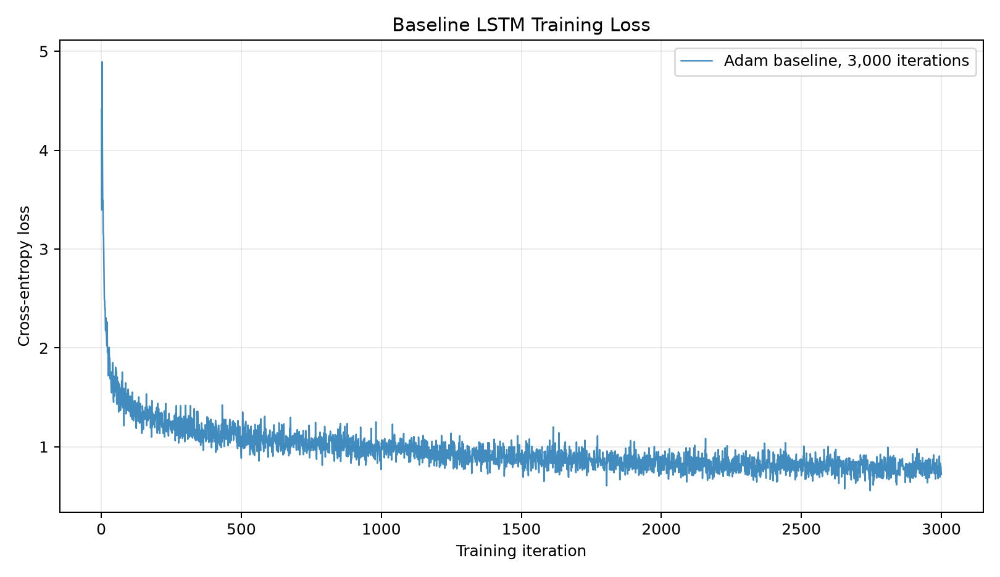

training_iterations_comparison.png


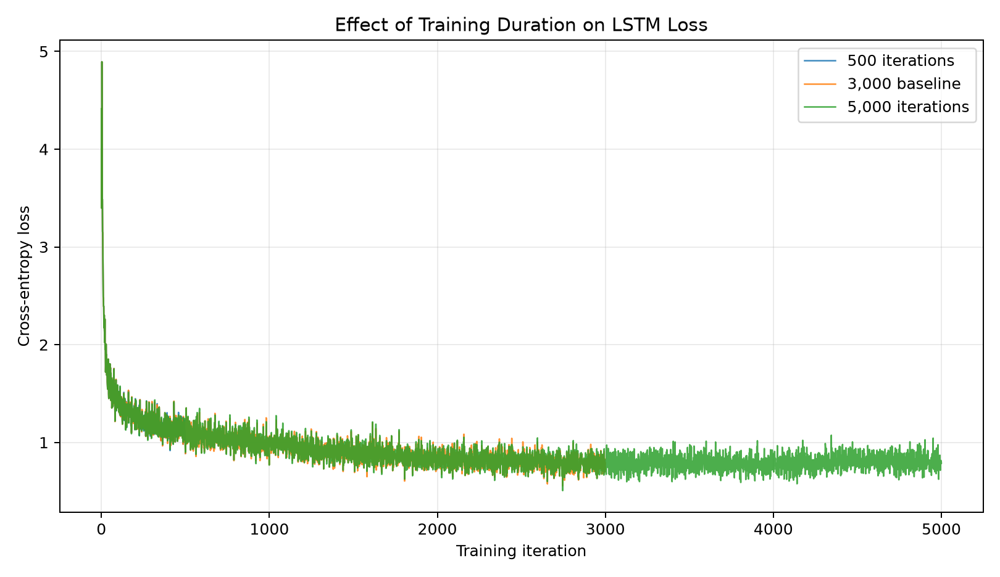

optimizer_loss_comparison.png


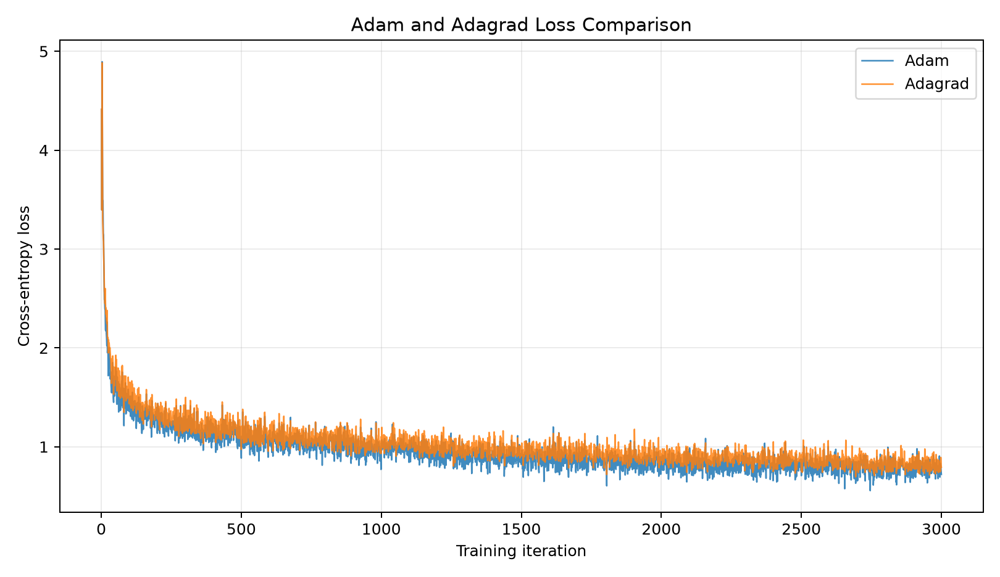

In [33]:
from IPython.display import Image, display
for plot_path in [
    FINAL_DIR / "baseline_loss_curve.png",
    FINAL_DIR / "training_iterations_comparison.png",
    FINAL_DIR / "optimizer_loss_comparison.png",
]:
    print(plot_path.name)
    display(Image(filename=str(plot_path)))
